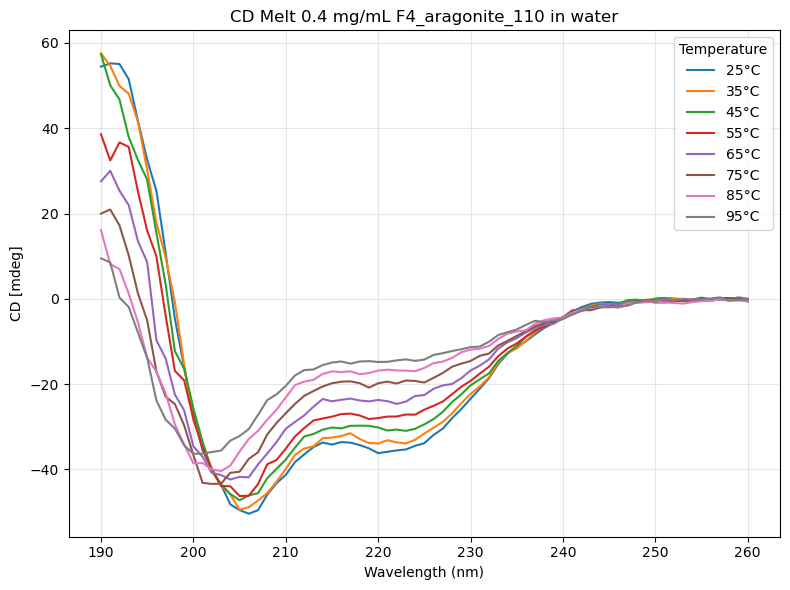

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# ===== Load data =====
file_path = "dhr_f4.csv"
df = pd.read_csv(file_path, header=None)

# First row (excluding first cell) = temperatures
temperatures = df.iloc[0, 1:].astype(float)

# First column (excluding first row) = wavelengths
wavelength = df.iloc[1:, 0].astype(float)

# CD signal matrix (everything else)
cd_values = df.iloc[1:, 1:].astype(float)

# ===== Plot =====
plt.figure(figsize=(8, 6))

for i, temp in enumerate(temperatures):
    plt.plot(wavelength, cd_values.iloc[:, i], label=f"{temp:g}°C")

plt.xlabel("Wavelength (nm)")
plt.ylabel("CD [mdeg]")
plt.title("CD Melt 0.4 mg/mL F4_aragonite_110 in water")
plt.legend(title="Temperature")
plt.grid(True, alpha=0.3)

plt.tight_layout()

# ===== Save figure =====
plt.savefig("cd_melt_plot.png", dpi=300, bbox_inches="tight")

plt.show()

Concentration: 1.560671e-05 M


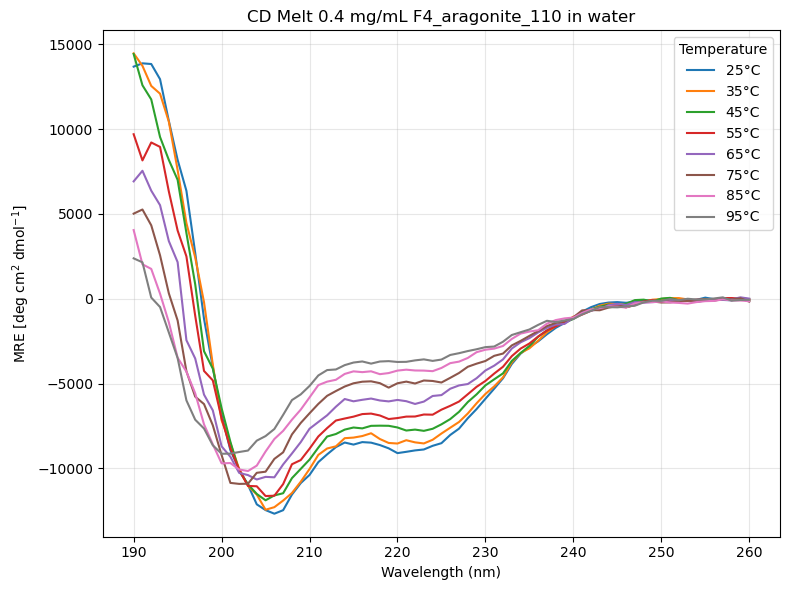

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ===== Input file =====
file_path = "dhr_f4.csv"

# ===== Experimental parameters =====
pathlength_mm = 1.0
mw_da = 25630         # 32.63 kDa
conc_mg_per_ml = 0.4
n_aa = 255

# ===== Convert concentration to mol/L (M) =====
# 0.4 mg/mL = 0.4 g/L
conc_g_per_l = conc_mg_per_ml
conc_M = conc_g_per_l / mw_da

print(f"Concentration: {conc_M:.6e} M")

# ===== Load data =====
df = pd.read_csv(file_path, header=None)

# First row (excluding first cell) = temperatures
temperatures = df.iloc[0, 1:].astype(float).values

# First column (excluding first row) = wavelengths
wavelength = df.iloc[1:, 0].astype(float).values

# CD signal matrix in mdeg
cd_values_mdeg = df.iloc[1:, 1:].astype(float)

# ===== Convert mdeg to MRE =====
# MRE [deg cm^2 dmol^-1] = CDsignal[mdeg] / (pathlength[mm] * concentration[M] * #aa)
mre_values = cd_values_mdeg / (pathlength_mm * conc_M * n_aa)

# ===== Save .xy file for each temperature =====
output_dir = Path("xy_output")
output_dir.mkdir(exist_ok=True)

for i, temp in enumerate(temperatures):
    out_df = pd.DataFrame({
        "Wavelength_nm": wavelength,
        "MRE_deg_cm2_dmol-1": mre_values.iloc[:, i].values
    })
    
    temp_str = f"{temp:g}".replace(".", "p")
    out_file = output_dir / f"cd_{temp_str}C.xy"
    
    # Save as two-column whitespace-delimited .xy file
    out_df.to_csv(out_file, sep="\t", index=False, header=False)

# ===== Plot =====
plt.figure(figsize=(8, 6))

for i, temp in enumerate(temperatures):
    plt.plot(wavelength, mre_values.iloc[:, i], label=f"{temp:g}°C")

plt.xlabel("Wavelength (nm)")
plt.ylabel(r"MRE [deg cm$^2$ dmol$^{-1}$]")
plt.title("CD Melt 0.4 mg/mL F4_aragonite_110 in water")
plt.legend(title="Temperature")
plt.grid(True, alpha=0.3)

plt.tight_layout()

# ===== Save figure =====
plt.savefig("cd_melt_plot_MRE.png", dpi=300, bbox_inches="tight")

plt.show()